# Canonical Transformer baseline
Reproduce the Transformer supplementary figures without launching training.


## Setup

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import sys

STYLE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/plotting/paper_style.py').is_file()) / 'src/plotting'
sys.path.insert(0, str(STYLE_DIR))
from paper_style import COLORS, configure_paper_style, save_dual, style_axis
configure_paper_style()

import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'experiments/model_selection/transformer/transfomer').is_dir())
SOURCE = ROOT / 'experiments/model_selection/transformer/transfomer'
OUT = ROOT / 'results/figures/transformer'
OUT.mkdir(parents=True, exist_ok=True)
SIZES = [8, 16, 24, 32, 40, 48, 56, 64, 72, 80]
SEEDS = list(range(202601, 202606))
CNS_RC = {}

def publish(fig, output_stem, *, tight=True):
    png, svg = save_dual(fig, output_stem, tight=tight)
    display(Image(filename=str(png), width=1100))
    plt.close(fig)

def save(fig, name, *, tight=True):
    for ax in fig.axes:
        if ax.axison: style_axis(ax)
    publish(fig, OUT/name, tight=tight)

def checked(summary, runs, key, metric):
    for _, row in summary.iterrows():
        group = runs[runs[key] == row[key]]
        assert sorted(group.seed.astype(int)) == SEEDS, (key, row[key])
        vals = group[metric].to_numpy(float)
        np.testing.assert_allclose([vals.mean(), vals.std(ddof=1)],
                                   [row[metric+'_mean'], row[metric+'_sd']], rtol=1e-6)
    return summary


## Consolidated Transformer screening
OFAT scans and interaction checks are compressed into three forest-style panels.


In [2]:
import csv

LABELS = {
    "batch_size": "Batch size", "lr": "Learning rate", "dropout": "Dropout",
    "weight_decay": "Weight decay", "model_size": r"$d_{model}$/heads",
    "num_layers": "Encoder layers", "ff_mult": "FF multiplier",
    "readout": "Readout", "position_encoding": "Position encoding",
}
ORDERS = {
    "batch_size": [16, 32, 40, 64, 128], "lr": [5e-5, 1e-4, 2e-4, 5e-4, 1e-3],
    "dropout": [0.0, 0.05, 0.1, 0.2], "weight_decay": [0.0, 1e-6, 1e-5, 1e-4],
    "model_size": [[64, 2], [128, 4], [192, 6], [256, 8]], "num_layers": [1, 2, 3, 4],
    "ff_mult": [2, 4, 6], "readout": ["cls", "mean", "cls_mean", "attention"],
    "position_encoding": ["none", "learnable", "sinusoidal"],
}

def read_csv(path):
    with Path(path).open(encoding='utf-8') as handle: return list(csv.DictReader(handle))

def value_label(family, value):
    if family == 'model_size': return f'{value[0]}/{value[1]}'
    if family in {'lr', 'weight_decay'}: return '0' if float(value) == 0 else f'{float(value):.0e}'
    if family == 'position_encoding': return {'none':'None','learnable':'Learned','sinusoidal':'Sinusoidal'}[value]
    if family == 'readout': return {'cls':'CLS','mean':'Mean','cls_mean':'CLS+mean','attention':'Attention'}[value]
    return f'{value:g}' if isinstance(value, float) else str(value)

def ofat_family_rows(rows, family):
    selected=[]
    for row in rows:
        cfg=json.loads(row['config_json'])
        value=[cfg['d_model'],cfg['num_heads']] if family=='model_size' else cfg[family]
        if cfg.get('varied_family')==family or row['config_id']=='anchor': selected.append({**row,'value':value})
    unique={json.dumps(item['value']):item for item in selected}
    return sorted(unique.values(),key=lambda item: ORDERS[family].index(item['value']))

def scan_panel(ax, labels, means, sds, title, letter, *, reference=None, rotate=0):
    x=np.arange(len(labels)); means=np.asarray(means); sds=np.asarray(sds)
    ax.errorbar(x,means,yerr=sds,fmt='o-',ms=7,lw=2.4,capsize=5,capthick=1.6,
                color=COLORS['blue'],markeredgecolor=COLORS['black'],markeredgewidth=.7)
    best=int(np.argmin(means))
    ax.scatter(x[best],means[best],s=95,marker='D',color=COLORS['orange'],
               edgecolor=COLORS['black'],linewidth=.8,zorder=4)
    if reference is not None:
        mean,sd=reference
        ax.axhspan(mean-sd,mean+sd,color=COLORS['orange'],alpha=.14,zorder=0)
        ax.axhline(mean,color=COLORS['orange'],lw=2,ls='--')
    ax.set_xticks(x,labels,rotation=rotate,ha='right' if rotate else 'center')
    ax.set_title(f'({letter}) {title}',loc='left',fontweight='bold')
    ax.set_ylabel('Validation MAPE (%)')
    ax.set_xlim(-.45,len(labels)-.55)
    lower=max(0,float(np.min(means-sds))*0.82); upper=float(np.max(means+sds))*1.13
    if reference is not None:
        lower=max(0,min(lower,(reference[0]-reference[1])*0.82)); upper=max(upper,(reference[0]+reference[1])*1.13)
    ax.set_ylim(lower,upper)
    style_axis(ax)

def interaction_label(prefix,cfg):
    if prefix=='lr_x_batch': return f"{cfg['lr']:.0e} / {cfg['batch_size']}"
    if prefix=='size_x_layers': return f"{cfg['d_model']}/{cfg['num_heads']} / L{cfg['num_layers']}"
    wd='0' if cfg['weight_decay']==0 else f"{cfg['weight_decay']:.0e}"
    return f"{cfg['dropout']:g} / {wd}"

ofat=read_csv(SOURCE/'ofat/summary/config_summary.csv')
interaction=read_csv(SOURCE/'interactions/summary/config_summary.csv')
families=['batch_size','lr','dropout','weight_decay','model_size','num_layers','ff_mult','readout','position_encoding']
interaction_specs=[('lr_x_batch','Learning rate / batch size'),('size_x_layers','Model size / layers'),('dropout_x_weight_decay','Dropout / weight decay')]

with plt.rc_context(CNS_RC):
    fig,axes=plt.subplots(3,4,figsize=(23,17),layout='constrained')
    panels=[]
    for family in families:
        items=ofat_family_rows(ofat,family)
        panels.append((LABELS[family],[value_label(family,z['value']) for z in items],
                       [float(z['validation_MAPE_mean']) for z in items],
                       [float(z['validation_MAPE_sd']) for z in items]))
    for prefix,title in interaction_specs:
        items=[row for row in interaction if row['config_id'].startswith(prefix+'__')]
        panels.append((title,[interaction_label(prefix,json.loads(row['config_json'])) for row in items],
                       [float(row['validation_MAPE_mean']) for row in items],
                       [float(row['validation_MAPE_sd']) for row in items]))
    slots=list(axes.flat)
    for i,(ax,(title,labels,means,sds)) in enumerate(zip(slots,panels)):
        scan_panel(ax,labels,means,sds,title,chr(97+i),rotate=28 if i in {7,8,9,10,11} else 0)
    publish(fig,OUT/'transformer_hyperparameter_screening')


## Consolidated local search and coordinate diagnostics
Selection stages and post-selection checks are compressed into two forest-style panels.


In [3]:
# Local-search and diagnostic results are reported in Supplementary Tables S13 and S14.


## Post-selection coordinate diagnostics
Included in Supplementary Fig. S1b.


In [4]:
# No separate local-search figure is generated.


## Supplementary Fig. S21: corrected block-stratified nested training sizes

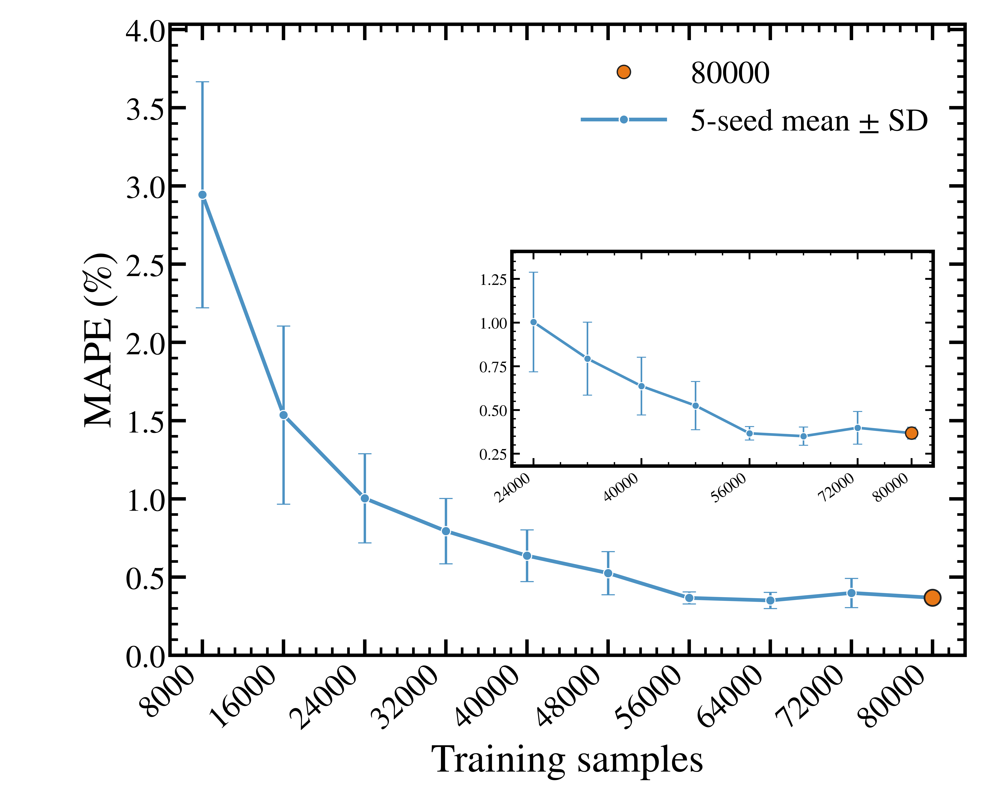

In [5]:
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
EXCLUDED_SIZE_K=70
def plot_one(
    sizes: np.ndarray,
    means: np.ndarray,
    sds: np.ndarray,
    *,
    ylabel: str,
    output_stem: Path,
) -> None:
    best_index = int(np.flatnonzero(sizes == 80)[0])
    positions = np.arange(len(sizes), dtype=float)
    best_x, best_y = float(positions[best_index]), float(means[best_index])

    fig, ax = plt.subplots(figsize=(10.5, 8.5), facecolor="white")
    ax.errorbar(
        positions,
        means,
        yerr=sds,
        color=COLORS["blue"],
        linewidth=2.8,
        marker="o",
        markersize=7,
        markerfacecolor=COLORS["blue"],
        markeredgecolor="#FFFFFF",
        markeredgewidth=0.8,
        capsize=5,
        capthick=1.8,
        elinewidth=1.8,
        zorder=2,
    )
    ax.scatter(
        [best_x], [best_y],
        s=150,
        color=COLORS["orange"],
        edgecolors=COLORS["black"],
        linewidths=1.3,
        zorder=4,
    )
    labels = [f"{int(size * 1000)}" for size in sizes]
    ax.set_xticks(positions, labels, rotation=42, ha="right")
    upper = max(float(np.max(means + sds)) * 1.10, float(np.max(means)) * 1.20)
    ax.set_xlim(-0.4, len(sizes) - 0.6)
    ax.set_ylim(0, upper)
    ax.set_xlabel("Training samples")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    style_axis(ax)

    legend_handles = [
        Line2D(
            [0], [0], marker="o", linestyle="none", markersize=10,
            markerfacecolor=COLORS["orange"], markeredgecolor=COLORS["black"],
            label="80000",
        ),
        Line2D(
            [0], [0], color=COLORS["blue"], linewidth=2.8, marker="o",
            markersize=7, markerfacecolor=COLORS["blue"], markeredgecolor="#FFFFFF",
            label="5-seed mean ± SD",
        ),
    ]
    ax.legend(handles=legend_handles, loc="upper right", bbox_to_anchor=(0.99, 0.99), handlelength=2.6)

    zoom_mask = sizes >= 24
    zoom_positions = positions[zoom_mask]
    zoom_sizes = sizes[zoom_mask]
    zoom_means = means[zoom_mask]
    zoom_sds = sds[zoom_mask]
    inset = ax.inset_axes([0.43, 0.30, 0.53, 0.34])
    inset.errorbar(
        zoom_positions,
        zoom_means,
        yerr=zoom_sds,
        color=COLORS["blue"],
        linewidth=2.0,
        marker="o",
        markersize=5.5,
        markerfacecolor=COLORS["blue"],
        markeredgecolor="#FFFFFF",
        markeredgewidth=0.7,
        capsize=3.5,
        capthick=1.2,
        elinewidth=1.2,
        zorder=2,
    )
    if sizes[best_index] >= 24:
        inset.scatter(
            [best_x], [best_y],
            s=85,
            color=COLORS["orange"],
            edgecolors=COLORS["black"],
            linewidths=1.0,
            zorder=4,
        )
    zoom_low = max(0.0, float(np.min(zoom_means - zoom_sds)))
    zoom_high = float(np.max(zoom_means + zoom_sds))
    zoom_pad = max((zoom_high - zoom_low) * 0.12, zoom_high * 0.04, 0.02)
    inset.set_xlim(zoom_positions[0] - 0.4, zoom_positions[-1] + 0.4)
    inset.set_ylim(max(0.0, zoom_low - zoom_pad), zoom_high + zoom_pad)
    inset_tick_sizes = [size for size in [24, 40, 56, 70, 72, 80] if size != EXCLUDED_SIZE_K]
    inset_tick_positions = [float(positions[np.where(sizes == size)[0][0]]) for size in inset_tick_sizes]
    inset.set_xticks(inset_tick_positions, [f"{int(size * 1000)}" for size in inset_tick_sizes], rotation=35, ha="right")
    inset.xaxis.set_minor_locator(AutoMinorLocator(2))
    style_axis(inset)
    inset.tick_params(which="major", labelsize=12, width=1.4, length=6)
    inset.tick_params(which="minor", width=1.0, length=3)

    fig.subplots_adjust(left=0.17, right=0.965, bottom=0.19, top=0.97)
    fig.savefig(output_stem.with_suffix(".pdf"), dpi=600, facecolor="white")
    publish(fig, output_stem, tight=False)
    plt.close(fig)
folder = ROOT / 'experiments/model_selection/block_stratified_nested/results/transformer/summary'
metric='validation_MAPE'
summary=pd.read_csv(folder/'validation_summary.csv')
runs=pd.read_csv(folder/'validation_per_run.csv')
plot_sizes=SIZES[:-1]
summary=summary[summary.size_k.isin(plot_sizes)].sort_values('size_k')
runs=runs[runs.size_k.isin(plot_sizes)]
assert summary.size_k.tolist()==plot_sizes and len(runs)==45
checked(summary,runs,'size_k',metric)
final_folder = ROOT / 'results/source_data/final_evaluation/transformer/transfomer/finalmode/80k/seed43_independent_2k_inference'
final_metrics = pd.read_csv(final_folder/'per_seed_metrics.csv').sort_values('seed')
assert final_metrics.seed.astype(int).tolist() == SEEDS
final_row = pd.DataFrame([{
    'size_k': 80, 'n': len(final_metrics),
    'validation_MAPE_mean': final_metrics.mape_percent.mean(),
    'validation_MAPE_sd': final_metrics.mape_percent.std(ddof=1),
    'validation_MAPE_sem': final_metrics.mape_percent.std(ddof=1) / np.sqrt(len(final_metrics)),
}])
summary = pd.concat([summary, final_row], ignore_index=True)
plot_one(summary.size_k.to_numpy(),summary[metric+'_mean'].to_numpy(),summary[metric+'_sd'].to_numpy(),
         ylabel='MAPE (%)',output_stem=OUT/'transformer_training_size')


## Final Transformer training histories (Supplementary Fig. S19)


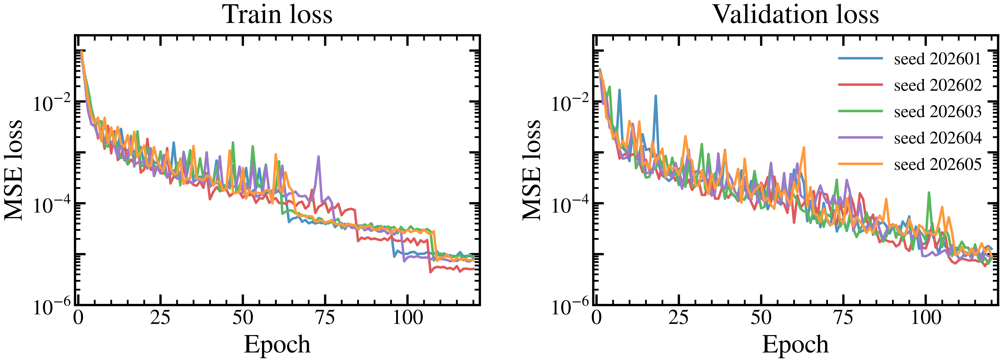

In [6]:
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter


def format_even_decade(value, _position):
    exponent = int(round(np.log10(value)))
    return rf"$10^{{{exponent}}}$" if exponent % 2 == 0 else ""


folder = SOURCE / "nested_data_scaling_80k_pool_seed42/training/runs/80k"
fig, (train_ax, val_ax) = plt.subplots(1, 2, figsize=(16, 6.6), facecolor="white")
for seed, color in zip(SEEDS, [COLORS[k] for k in ("blue", "red", "green", "purple", "amber")], strict=True):
    history = pd.read_csv(folder / f"seed{seed}/training_history.csv")
    assert history.epoch.tolist() == list(range(1, 121))
    train_ax.plot(history.epoch, history.train_log_mse, color=color, label=f"seed {seed}")
    val_ax.plot(history.epoch, history.validation_log_mse, color=color, label=f"seed {seed}")
for ax, title in ((train_ax, "Train loss"), (val_ax, "Validation loss")):
    ax.set(xlim=(-1, 122), ylim=(1e-6, 2e-1), yscale="log", xlabel="Epoch", ylabel="MSE loss")
    ax.set_box_aspect(2 / 3)
    ax.set_title(title, fontsize=32, pad=14)
    style_axis(ax)
    ax.yaxis.set_major_locator(LogLocator(base=10, numticks=12))
    ax.yaxis.set_major_formatter(FuncFormatter(format_even_decade))
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=100))
    ax.yaxis.set_minor_formatter(NullFormatter())
val_ax.legend(loc="upper right", fontsize=20, handlelength=2.4, handletextpad=0.7)
fig.subplots_adjust(left=0.08, right=0.99, bottom=0.18, top=0.88, wspace=0.28)
output = OUT / "final_transformer_training_histories"
png, svg = save_dual(fig, output)
fig.savefig(output.with_suffix(".pdf"), dpi=600, facecolor="white")
display(Image(filename=str(png), width=1100))
plt.close(fig)


## Frozen seed43 test: per-run metrics and representative parity

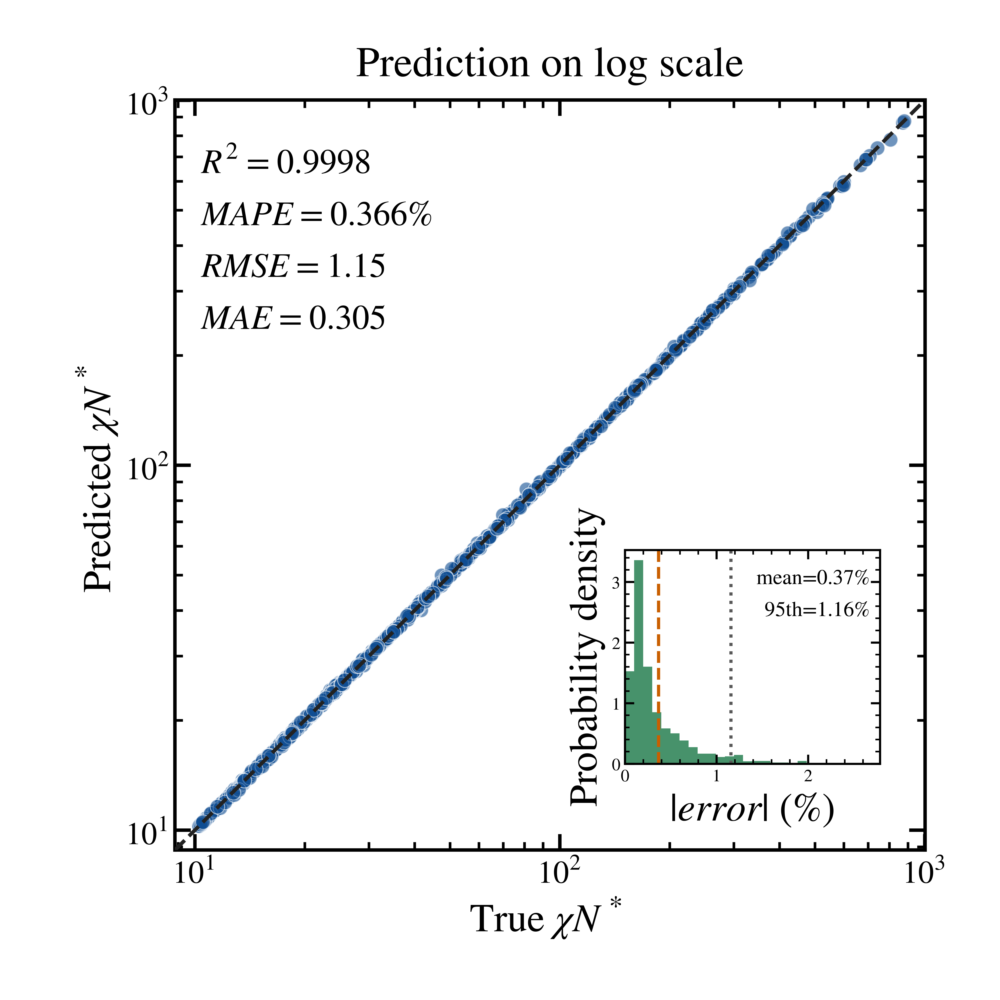

In [7]:
folder = SOURCE / 'finalmode/80k/seed43_independent_2k_inference'
metrics = pd.read_csv(folder / 'per_seed_metrics.csv').sort_values('seed')
assert metrics.seed.tolist() == SEEDS
for seed in SEEDS:
    data = pd.read_csv(folder / f'seed{seed}_seed43_independent_predictions.csv')
    assert len(data) == 2000
    mape = 100*np.mean(np.abs(data.pred-data.true)/np.abs(data.true))
    np.testing.assert_allclose(mape, metrics.loc[metrics.seed==seed, 'mape_percent'].iloc[0], rtol=2e-6)
np.testing.assert_allclose([metrics.mape_percent.mean(), metrics.mape_percent.std(ddof=1)],
                           [0.3679, 0.0343], atol=0.00005)

import csv
INFERENCE=folder
def load_predictions(path: Path) -> tuple[np.ndarray, np.ndarray]:
    with path.open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    true = np.asarray([float(row["true"]) for row in rows])
    pred = np.asarray([float(row["pred"]) for row in rows])
    if np.any(true <= 0) or np.any(pred <= 0):
        raise ValueError(f"Log-scale parity requires positive predictions: {path}")
    return true, pred

def plot_parity(seed: int) -> None:
    stem = f"seed{seed}_seed43_independent"
    true, pred = load_predictions(INFERENCE / f"{stem}_predictions.csv")
    metric = json.loads((INFERENCE / f"{stem}.json").read_text(encoding="utf-8"))
    rel = np.abs(pred - true) / np.clip(np.abs(true), 1e-12, None) * 100
    mean_error = float(rel.mean())
    p95_error = float(np.percentile(rel, 95))
    upper = float(np.percentile(rel, 99.5))
    low = min(float(true.min()), float(pred.min())) * 0.86
    high = max(float(true.max()), float(pred.max())) * 1.14

    fig, ax = plt.subplots(figsize=(10.5, 10.5), facecolor="white")
    ax.scatter(true, pred, s=120, color=COLORS["parity_blue"], alpha=0.60,
               edgecolors="#FFFFFF", linewidths=0.7, zorder=2)
    ax.plot((low, high), (low, high), "--", color=COLORS["black"], lw=2.8, zorder=3)
    ax.set(xscale="log", yscale="log", xlim=(low, high), ylim=(low, high),
           xlabel=r"True $\chi N^*$", ylabel=r"Predicted $\chi N^*$")
    ax.set_box_aspect(1)
    ax.set_title("Prediction on log scale", fontsize=32, pad=18)
    ax.text(0.035, 0.955,
            "\n".join((rf"$R^2={metric['r2']:.4f}$", rf"$MAPE={metric['mape_percent']:.3f}\%$",
                       rf"$RMSE={metric['rmse']:.2f}$", rf"$MAE={metric['mae']:.3f}$")),
            transform=ax.transAxes, ha="left", va="top", fontsize=26)
    style_axis(ax)

    inset = ax.inset_axes([0.60, 0.115, 0.34, 0.285])
    inset.hist(rel, bins=np.linspace(0, upper, 28), density=True, color=COLORS["density_green"],
               alpha=0.82, edgecolor="none")
    inset.axvline(mean_error, color=COLORS["mean_orange"], ls="--", lw=2.4)
    inset.axvline(p95_error, color="0.35", ls=":", lw=2.4)
    inset.set(xlim=(0, upper * 1.04), xlabel=r"$|error|$ (%)", ylabel="Probability density")
    style_axis(inset)
    inset.tick_params(axis="both", which="major", labelsize=13, length=7, width=1.6)
    inset.tick_params(axis="both", which="minor", length=3.5, width=1.2)
    for spine in inset.spines.values():
        spine.set_linewidth(1.6)
    inset.text(0.96, 0.94, f"mean={mean_error:.2f}%\n95th={p95_error:.2f}%",
               transform=inset.transAxes, ha="right", va="top", fontsize=16)
    fig.subplots_adjust(left=0.16, right=0.94, bottom=0.15, top=0.90)
    publish(fig, OUT / "Transformer_seed43_final_test", tight=False)
    plt.close(fig)
plot_parity(202603)


## Block-count extrapolation: representative checkpoint from the manuscript

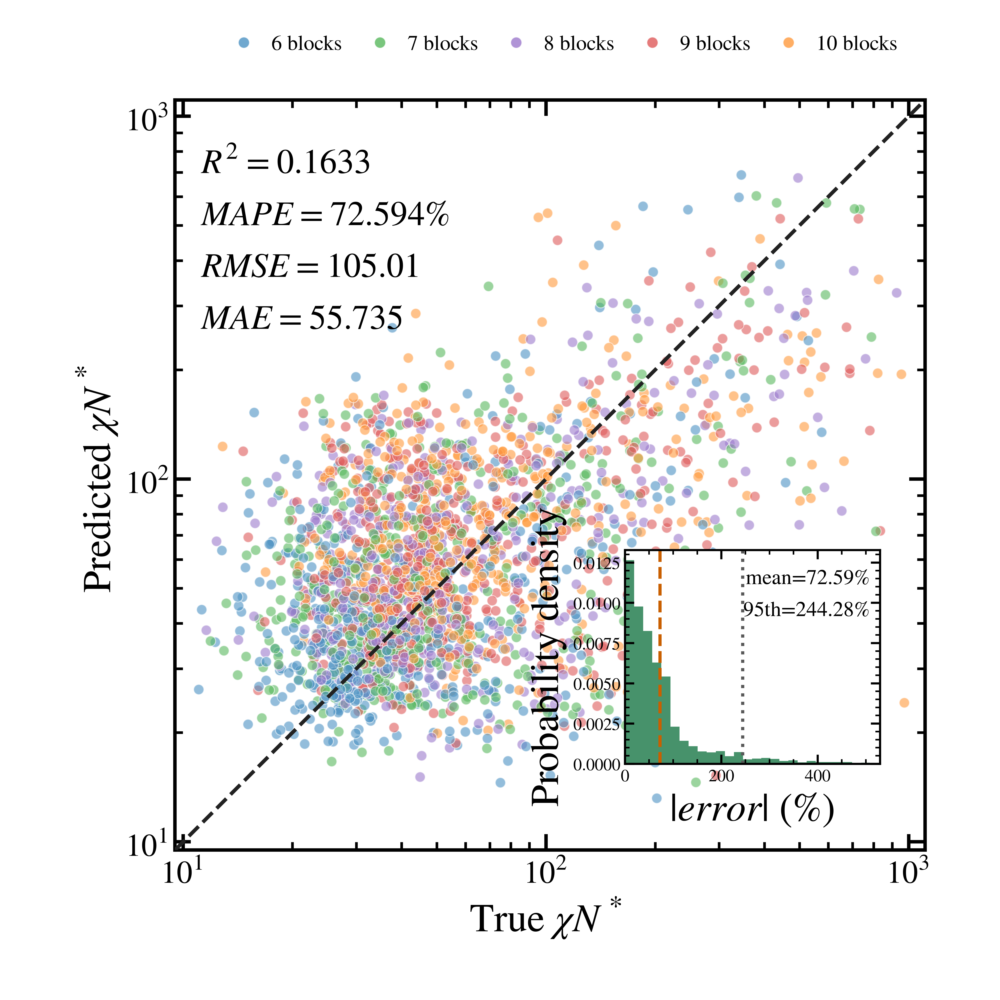

In [8]:
import csv
INFERENCE=SOURCE/'finalmode/80k/transfer_6to10blocks_inference'
BLOCK_COLORS = {6: COLORS["blue"], 7: COLORS["green"], 8: COLORS["purple"], 9: COLORS["red"], 10: COLORS["amber"]}

def draw(seed: int) -> None:
    stem = f"seed{seed}_transfer_6to10blocks"
    with (INFERENCE / f"{stem}_predictions.csv").open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    true = np.asarray([float(row["y_true"]) for row in rows])
    pred = np.asarray([float(row["y_pred"]) for row in rows])
    blocks = np.asarray([int(row["block_count"]) for row in rows])
    result = json.loads((INFERENCE / f"{stem}.json").read_text(encoding="utf-8"))
    rel = np.abs(pred - true) / np.clip(np.abs(true), 1e-12, None) * 100
    lower, upper = min(float(true.min()), float(pred.min())) * 0.86, max(float(true.max()), float(pred.max())) * 1.14
    order = np.random.default_rng(seed).permutation(len(true))
    fig, ax = plt.subplots(figsize=(10.5, 10.5), facecolor="white")
    ax.scatter(true[order], pred[order], s=60, c=[BLOCK_COLORS[int(value)] for value in blocks[order]],
               alpha=0.60, edgecolors="#FFFFFF", linewidths=0.7, zorder=2)
    ax.plot((lower, upper), (lower, upper), "--", color=COLORS["black"], lw=2.8, zorder=3)
    ax.set(xscale="log", yscale="log", xlim=(lower, upper), ylim=(lower, upper),
           xlabel=r"True $\chi N^*$", ylabel=r"Predicted $\chi N^*$")
    ax.set_box_aspect(1)
    ax.text(0.035, 0.955, "\n".join((rf"$R^2={result['R2']:.4f}$", rf"$MAPE={result['MAPE']:.3f}\%$",
                                       rf"$RMSE={result['RMSE']:.2f}$", rf"$MAE={result['MAE']:.3f}$")),
            transform=ax.transAxes, ha="left", va="top", fontsize=26)
    style_axis(ax)
    handles = [Line2D([0], [0], marker="o", linestyle="none", markersize=10, markerfacecolor=BLOCK_COLORS[count],
                      markeredgecolor="#FFFFFF", markeredgewidth=0.7, alpha=0.8, label=f"{count} blocks")
               for count in sorted(BLOCK_COLORS)]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.56, 0.985), ncol=5,
               fontsize=16, columnspacing=0.8, handletextpad=0.30, markerscale=0.85)
    inset = ax.inset_axes([0.60, 0.115, 0.34, 0.285])
    p995, mean_error, p95 = float(np.percentile(rel, 99.5)), float(rel.mean()), float(np.percentile(rel, 95))
    inset.hist(rel, bins=np.linspace(0, p995, 28), density=True, color=COLORS["density_green"], alpha=0.82, edgecolor="none")
    inset.axvline(mean_error, color=COLORS["mean_orange"], ls="--", lw=2.4)
    inset.axvline(p95, color="0.35", ls=":", lw=2.4)
    inset.set(xlim=(0, p995 * 1.04), xlabel=r"$|error|$ (%)", ylabel="Probability density")
    style_axis(inset)
    inset.tick_params(axis="both", which="major", labelsize=13, length=7, width=1.6)
    inset.tick_params(axis="both", which="minor", length=3.5, width=1.2)
    for spine in inset.spines.values(): spine.set_linewidth(1.6)
    inset.text(0.96, 0.94, f"mean={mean_error:.2f}%\n95th={p95:.2f}%", transform=inset.transAxes,
               ha="right", va="top", fontsize=16)
    fig.subplots_adjust(left=0.16, right=0.94, bottom=0.15, top=0.90)
    publish(fig, OUT / "Transformer_block_extrapolation_seed202603", tight=False)
    plt.close(fig)
draw(202603)
